# Data Science Assignment: Session 10
## Topic: Bayes' Theorem (Basic)

**Student Name:** Atharv Chaudhari  
**Course:** Data Science & Statistics  
**Session:** SESSION 10 - Bayes Theorem (Basic)  

---

### Overview: The Mathematics of Conditional Probability & Bayesian Inference

**Bayes' Theorem** provides a rigorous mathematical framework for updating our degree of belief in a hypothesis ($A$) given new observable evidence ($B$). It forms the backbone of diagnostic testing, spam filtering, fraud detection, and Bayesian machine learning.

$$\mathbf{P(A \mid B) = \frac{P(B \mid A) \cdot P(A)}{P(B)}}$$

#### Key Mathematical Components:
1. **Prior Probability $P(A)$:** Initial baseline probability of hypothesis $A$ before seeing new evidence.
2. **Likelihood $P(B \mid A)$:** Probability of observing evidence $B$ given that hypothesis $A$ is true.
3. **Marginal Evidence $P(B)$:** Total probability of observing evidence $B$ across all possible states of nature (derived via the **Law of Total Probability**):
   $$P(B) = P(B \mid A) \cdot P(A) + P(B \mid A^c) \cdot P(A^c)$$
4. **Posterior Probability $P(A \mid B)$:** The revised, updated probability of hypothesis $A$ after observing evidence $B$.

---


## Task 1: Bayes' Posterior Function
> **Problem Statement:** Write a Python function `bayes_posterior(prior, likelihood, evidence)` that calculates and returns the posterior probability using Bayes theorem formula for given values.


In [1]:
def bayes_posterior(prior, likelihood, evidence):
    """
    Calculates the posterior probability P(A|B) using Bayes' Theorem.
    
    Formula:
        P(A|B) = (P(B|A) * P(A)) / P(B)
        Posterior = (Likelihood * Prior) / Evidence
        
    Parameters:
    -----------
    prior : float
        Prior probability of hypothesis A, P(A), where 0 <= prior <= 1.
    likelihood : float
        Likelihood of observing evidence B given hypothesis A is true, P(B|A), where 0 <= likelihood <= 1.
    evidence : float
        Total marginal probability of observing evidence B, P(B), where 0 < evidence <= 1.
        
    Returns:
    --------
    float:
        Posterior probability P(A|B).
    """
    # Input validation
    if not (0.0 <= prior <= 1.0):
        raise ValueError(f"Prior probability must be between 0 and 1, got {prior}")
    if not (0.0 <= likelihood <= 1.0):
        raise ValueError(f"Likelihood must be between 0 and 1, got {likelihood}")
    if evidence <= 0.0 or evidence > 1.0:
        raise ValueError(f"Evidence must be strictly greater than 0 and <= 1, got {evidence}")
        
    posterior = (likelihood * prior) / evidence
    return posterior


# Verification and Benchmark Tests
print("=" * 68)
print("TASK 1: TESTING bayes_posterior() WITH BENCHMARK TEST CASES")
print("=" * 68)

test_cases = [
    {
        "name": "Standard Medical Test (Rare Disease)",
        "prior": 0.01,         # 1% prevalence
        "likelihood": 0.95,    # 95% test sensitivity
        "evidence": 0.0594     # Total positive test rate
    },
    {
        "name": "Fair vs Biased Coin Identification",
        "prior": 0.50,         # 50% chance coin is biased
        "likelihood": 0.80,    # 80% chance of Heads given biased coin
        "evidence": 0.65       # Overall Heads probability
    },
    {
        "name": "Factory Machine Defect Diagnosis",
        "prior": 0.05,         # 5% defective parts
        "likelihood": 0.90,    # 90% alarm trigger given defect
        "evidence": 0.14       # Overall alarm trigger rate
    }
]

for i, tc in enumerate(test_cases, 1):
    res = bayes_posterior(tc["prior"], tc["likelihood"], tc["evidence"])
    print(f"Test Case {i}: {tc['name']}")
    print(f"  - Prior P(A)        : {tc['prior']:.4f} ({tc['prior']*100:.2f}%)")
    print(f"  - Likelihood P(B|A) : {tc['likelihood']:.4f} ({tc['likelihood']*100:.2f}%)")
    print(f"  - Evidence P(B)     : {tc['evidence']:.4f} ({tc['evidence']*100:.2f}%)")
    print(f"  => Posterior P(A|B) : {res:.4f} ({res*100:.2f}%)\n")



TASK 1: TESTING bayes_posterior() WITH BENCHMARK TEST CASES
Test Case 1: Standard Medical Test (Rare Disease)
  - Prior P(A)        : 0.0100 (1.00%)
  - Likelihood P(B|A) : 0.9500 (95.00%)
  - Evidence P(B)     : 0.0594 (5.94%)
  => Posterior P(A|B) : 0.1599 (15.99%)

Test Case 2: Fair vs Biased Coin Identification
  - Prior P(A)        : 0.5000 (50.00%)
  - Likelihood P(B|A) : 0.8000 (80.00%)
  - Evidence P(B)     : 0.6500 (65.00%)
  => Posterior P(A|B) : 0.6154 (61.54%)

Test Case 3: Factory Machine Defect Diagnosis
  - Prior P(A)        : 0.0500 (5.00%)
  - Likelihood P(B|A) : 0.9000 (90.00%)
  - Evidence P(B)     : 0.1400 (14.00%)
  => Posterior P(A|B) : 0.3214 (32.14%)



## Task 2: Swiggy Premium Restaurant Scenario
> **Problem Statement:** Given the following scenario: On Swiggy, 10% of restaurants are 'premium', and 80% of premium restaurants offer a discount, while only 20% of regular restaurants do. If you see a discount, use Bayes theorem in code to find the probability that the restaurant is premium.  
> *Hint: Define prior, likelihood, and evidence in your code with comments.*

---

### Step-by-Step Mathematical Derivation:
1. **Hypotheses:**
   - $A_1$: Restaurant is **Premium**
   - $A_2$: Restaurant is **Regular** ($A_2 = A_1^c$)
2. **Observable Evidence:**
   - $B$: Restaurant offers a **Discount**
3. **Priors:**
   - $P(\text{Premium}) = 0.10$
   - $P(\text{Regular}) = 1.0 - 0.10 = 0.90$
4. **Likelihoods:**
   - $P(\text{Discount} \mid \text{Premium}) = 0.80$
   - $P(\text{Discount} \mid \text{Regular}) = 0.20$
5. **Marginal Evidence (Law of Total Probability):**
   $$P(\text{Discount}) = P(\text{Discount} \mid \text{Premium}) \cdot P(\text{Premium}) + P(\text{Discount} \mid \text{Regular}) \cdot P(\text{Regular})$$
   $$P(\text{Discount}) = (0.80 \times 0.10) + (0.20 \times 0.90) = 0.08 + 0.18 = 0.26 \; (26\%)$$
6. **Posterior Probability:**
   $$P(\text{Premium} \mid \text{Discount}) = \frac{P(\text{Discount} \mid \text{Premium}) \cdot P(\text{Premium})}{P(\text{Discount})} = \frac{0.80 \times 0.10}{0.26} = \frac{0.08}{0.26} \approx 0.3077 \; (30.77\%)$$



-----------------------------------------------------------------
SWIGGY BAYES' THEOREM CALCULATION RESULTS:
-----------------------------------------------------------------
1. Prior Probability P(Premium)               : 0.1000  (10.0%)
2. Prior Probability P(Regular)               : 0.9000  (90.0%)
3. Likelihood P(Discount | Premium)           : 0.8000  (80.0%)
4. Likelihood P(Discount | Regular)           : 0.2000  (20.0%)
5. Total Marginal Evidence P(Discount)        : 0.2600  (26.0%)
   [Discounts from Premium: 8.0% | Discounts from Regular: 18.0%]
6. POSTERIOR PROBABILITY P(Premium | Discount): 0.3077  (30.77%)
-----------------------------------------------------------------
Insight: Seeing a discount increases the chance the restaurant is premium from 10.0% to 30.77% (more than 3x update!).


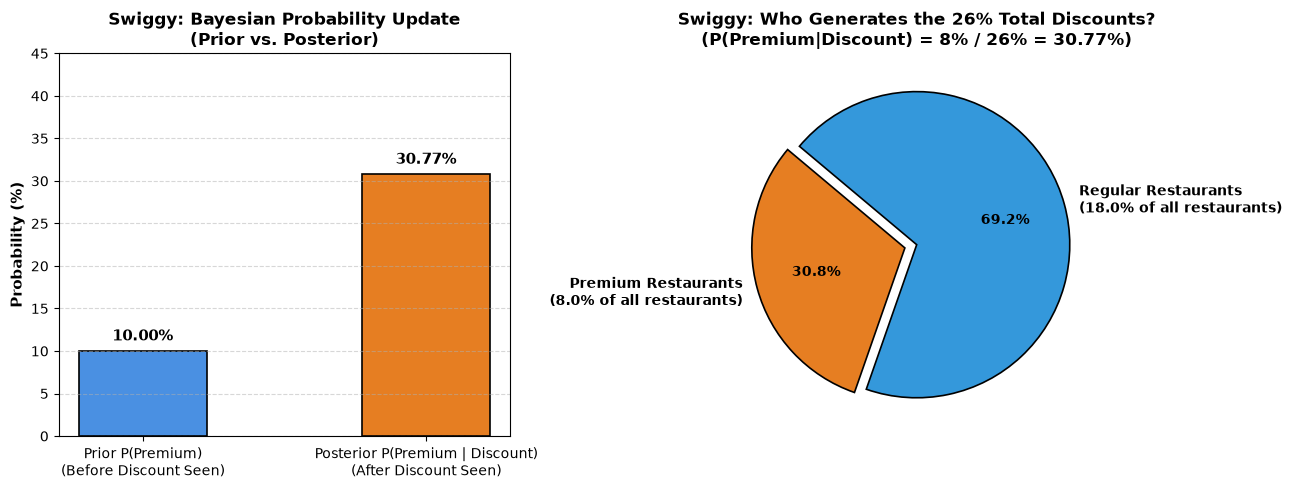

In [2]:
import matplotlib.pyplot as plt

# ==============================================================================
# TASK 2: SWIGGY RESTAURANT DISCOUNT POSTERIOR ANALYSIS
# ==============================================================================

# STEP 1: Define Prior Probabilities P(A)
# ------------------------------------------------------------------------------
# P(Premium): Prior probability that any randomly chosen restaurant is 'premium' (10%)
prior_premium = 0.10

# P(Regular): Complementary prior probability that restaurant is 'regular' (90%)
prior_regular = 1.0 - prior_premium  # 0.90


# STEP 2: Define Likelihoods P(B | A)
# ------------------------------------------------------------------------------
# P(Discount | Premium): Likelihood that a premium restaurant offers a discount (80%)
likelihood_discount_given_premium = 0.80

# P(Discount | Regular): Likelihood that a regular restaurant offers a discount (20%)
likelihood_discount_given_regular = 0.20


# STEP 3: Define Marginal Evidence P(B) via Law of Total Probability
# ------------------------------------------------------------------------------
# P(Discount): Total probability of encountering a discount across all restaurants
# P(Discount) = P(Discount | Premium)*P(Premium) + P(Discount | Regular)*P(Regular)
joint_premium_discount = likelihood_discount_given_premium * prior_premium   # 0.08
joint_regular_discount = likelihood_discount_given_regular * prior_regular   # 0.18
evidence_discount = joint_premium_discount + joint_regular_discount         # 0.26


# STEP 4: Compute Posterior Probability P(A | B) Using bayes_posterior()
# ------------------------------------------------------------------------------
# P(Premium | Discount): Probability that the restaurant is premium, given it offers a discount
posterior_premium_given_discount = bayes_posterior(
    prior=prior_premium,
    likelihood=likelihood_discount_given_premium,
    evidence=evidence_discount
)

print("-" * 65)
print("SWIGGY BAYES' THEOREM CALCULATION RESULTS:")
print("-" * 65)
print(f"1. Prior Probability P(Premium)               : {prior_premium:.4f}  ({prior_premium*100:.1f}%)")
print(f"2. Prior Probability P(Regular)               : {prior_regular:.4f}  ({prior_regular*100:.1f}%)")
print(f"3. Likelihood P(Discount | Premium)           : {likelihood_discount_given_premium:.4f}  ({likelihood_discount_given_premium*100:.1f}%)")
print(f"4. Likelihood P(Discount | Regular)           : {likelihood_discount_given_regular:.4f}  ({likelihood_discount_given_regular*100:.1f}%)")
print(f"5. Total Marginal Evidence P(Discount)        : {evidence_discount:.4f}  ({evidence_discount*100:.1f}%)")
print(f"   [Discounts from Premium: {joint_premium_discount*100:.1f}% | Discounts from Regular: {joint_regular_discount*100:.1f}%]")
print(f"6. POSTERIOR PROBABILITY P(Premium | Discount): {posterior_premium_given_discount:.4f}  ({posterior_premium_given_discount*100:.2f}%)")
print("-" * 65)
print(f"Insight: Seeing a discount increases the chance the restaurant is premium from 10.0% to {posterior_premium_given_discount*100:.2f}% (more than 3x update!).")

# VISUALIZATION: Prior vs. Posterior & Discount Breakdown
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Prior vs Posterior Probability
bars = ax1.bar(
    ['Prior P(Premium)\n(Before Discount Seen)', 'Posterior P(Premium | Discount)\n(After Discount Seen)'],
    [prior_premium * 100, posterior_premium_given_discount * 100],
    color=['#4a90e2', '#e67e22'],
    width=0.45,
    edgecolor='black',
    linewidth=1.2
)
ax1.set_ylabel('Probability (%)', fontsize=11, fontweight='bold')
ax1.set_title('Swiggy: Bayesian Probability Update\n(Prior vs. Posterior)', fontsize=12, fontweight='bold')
ax1.set_ylim(0, 45)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    height = bar.get_height()
    ax1.annotate(f'{height:.2f}%',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 5), textcoords='offset points',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

# Subplot 2: Composition of Total Discount Evidence
sizes = [joint_premium_discount * 100, joint_regular_discount * 100]
labels = [f'Premium Restaurants\n({joint_premium_discount*100:.1f}% of all restaurants)',
          f'Regular Restaurants\n({joint_regular_discount*100:.1f}% of all restaurants)']
colors = ['#e67e22', '#3498db']
explode = (0.08, 0)

wedges, texts, autotexts = ax2.pie(
    sizes,
    explode=explode,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=140,
    textprops=dict(color='black', fontweight='bold'),
    wedgeprops=dict(edgecolor='black', linewidth=1.2)
)
ax2.set_title('Swiggy: Who Generates the 26% Total Discounts?\n(P(Premium|Discount) = 8% / 26% = 30.77%)',
              fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()



## Task 3: Spam Detection Simulation with Bayes' Theorem
> **Problem Statement:** Simulate a basic spam detection filter: Given a list of 20 email subjects (some spam, some not), and the probability that 'free' appears in spam vs non-spam emails, write code to calculate the probability an email is spam if it contains 'free', using Bayes theorem.

---

### Machine Learning Context: Naive Bayes Spam Filter
In Natural Language Processing (NLP), Bayesian spam filters compute:

$$\mathbf{P(\text{Spam} \mid \text{'free'}) = \frac{P(\text{'free'} \mid \text{Spam}) \cdot P(\text{Spam})}{P(\text{'free'})}}$$

Where:
- $P(\text{Spam})$ = Prior probability of any email being spam.
- $P(\text{'free'} \mid \text{Spam})$ = Empirical likelihood that word `'free'` occurs in spam emails.
- $P(\text{'free'} \mid \text{Ham})$ = Empirical likelihood that word `'free'` occurs in non-spam (Ham) emails.
- $P(\text{'free'})$ = Total evidence calculated as:
  $$P(\text{'free'}) = P(\text{'free'} \mid \text{Spam}) \cdot P(\text{Spam}) + P(\text{'free'} \mid \text{Ham}) \cdot P(\text{Ham})$$



TASK 3: SPAM DETECTION FILTER RESULTS (20 SIMULATED EMAILS)
Total Dataset Size                 : 20 emails
  - Spam Count                     : 8 (40.0%)
  - Ham Count                      : 12 (60.0%)
Emails Containing 'free'           : 8 out of 20
  - Spam emails with 'free'        : 6 out of 8
  - Ham emails with 'free'         : 2 out of 12
----------------------------------------------------------------------
Prior Probability P(Spam)          : 0.4000  (40.0%)
Likelihood P('free' | Spam)        : 0.7500  (75.0%)
Likelihood P('free' | Ham)         : 0.1667  (16.7%)
Total Evidence P('free')           : 0.4000  (40.0%)
POSTERIOR P(Spam | 'free')         : 0.7500  (75.00%)

SAMPLE SIMULATED EMAIL SUBJECTS TABLE:
   label  contains_free                                                        subject
0   Spam           True          Congratulations! Claim your FREE vacation tickets now
1   Spam           True            Get 100% free crypto coins with no deposit required
2   Spam      

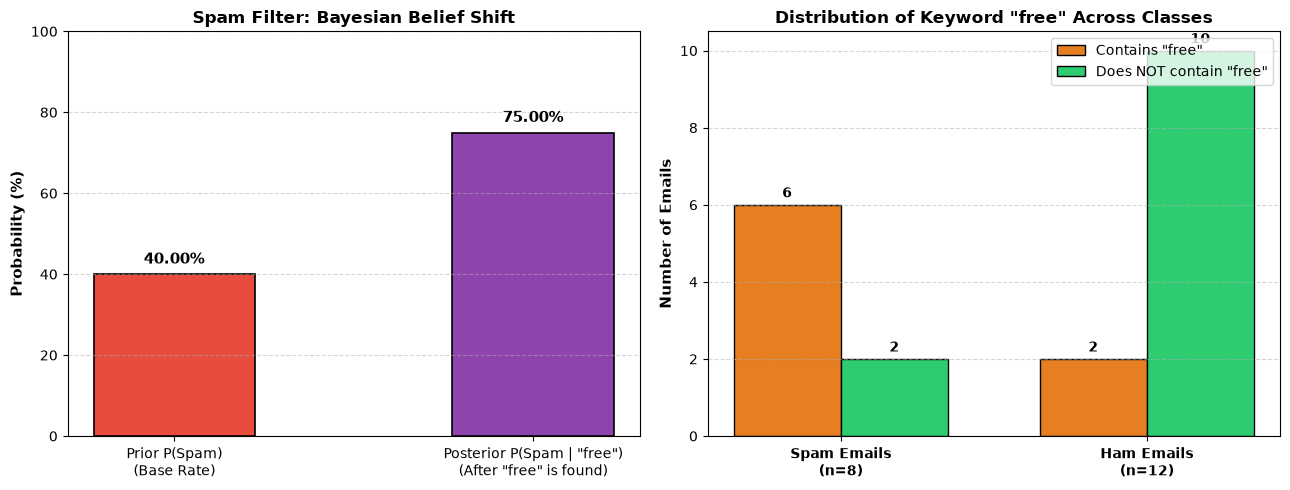

In [3]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Construct realistic simulation dataset of 20 email subjects
emails_data = [
    # 8 SPAM EMAILS
    {"subject": "Congratulations! Claim your FREE vacation tickets now", "label": "Spam"},
    {"subject": "Get 100% free crypto coins with no deposit required", "label": "Spam"},
    {"subject": "Exclusive free trial of luxury anti-aging cream", "label": "Spam"},
    {"subject": "You have won a free iPhone 15 Pro Max giveaway", "label": "Spam"},
    {"subject": "Urgent: Click here for your free gift voucher worth $500", "label": "Spam"},
    {"subject": "Instant cash loan approved with zero fees", "label": "Spam"},
    {"subject": "Your lottery winning number is 984210 - claim prize", "label": "Spam"},
    {"subject": "Download this free software to speed up your PC instantly", "label": "Spam"},
    
    # 12 HAM (NON-SPAM) EMAILS
    {"subject": "Meeting agenda for tomorrow's engineering sprint planning", "label": "Ham"},
    {"subject": "Swiggy order delivered: Enjoy your meal!", "label": "Ham"},
    {"subject": "Are you free to catch up for coffee this Thursday afternoon?", "label": "Ham"},
    {"subject": "Project update: Q3 data science milestones completed", "label": "Ham"},
    {"subject": "Feel free to check out the updated design wireframes attached", "label": "Ham"},
    {"subject": "Your monthly credit card statement is now available", "label": "Ham"},
    {"subject": "Flight booking confirmation: Mumbai to Bengaluru", "label": "Ham"},
    {"subject": "Electricity bill generated: Due date November 5", "label": "Ham"},
    {"subject": "GitHub security alert: New SSH key added to your profile", "label": "Ham"},
    {"subject": "Invitation: Guest lecture on Machine Learning fundamentals", "label": "Ham"},
    {"subject": "Quarterly performance feedback review document", "label": "Ham"},
    {"subject": "Team lunch scheduled for this Friday at 1 PM", "label": "Ham"}
]

# Create DataFrame
df_emails = pd.DataFrame(emails_data)

# Check for presence of 'free' as an independent word (case-insensitive regex)
df_emails['contains_free'] = df_emails['subject'].apply(
    lambda text: bool(re.search(r'\bfree\b', text, flags=re.IGNORECASE))
)

# 2. Empirical Frequency Calculations
total_emails = len(df_emails)
spam_df = df_emails[df_emails['label'] == 'Spam']
ham_df = df_emails[df_emails['label'] == 'Ham']

count_spam = len(spam_df)
count_ham = len(ham_df)

count_spam_with_free = spam_df['contains_free'].sum()
count_ham_with_free = ham_df['contains_free'].sum()
count_total_with_free = df_emails['contains_free'].sum()

# Step A: Priors
prior_spam = count_spam / total_emails
prior_ham = count_ham / total_emails

# Step B: Likelihoods
likelihood_free_given_spam = count_spam_with_free / count_spam
likelihood_free_given_ham = count_ham_with_free / count_ham

# Step C: Total Evidence P('free')
evidence_free = count_total_with_free / total_emails

# Step D: Posterior P(Spam | 'free')
posterior_spam_given_free = bayes_posterior(
    prior=prior_spam,
    likelihood=likelihood_free_given_spam,
    evidence=evidence_free
)

print("=" * 70)
print("TASK 3: SPAM DETECTION FILTER RESULTS (20 SIMULATED EMAILS)")
print("=" * 70)
print(f"Total Dataset Size                 : {total_emails} emails")
print(f"  - Spam Count                     : {count_spam} ({prior_spam*100:.1f}%)")
print(f"  - Ham Count                      : {count_ham} ({prior_ham*100:.1f}%)")
print(f"Emails Containing 'free'           : {count_total_with_free} out of {total_emails}")
print(f"  - Spam emails with 'free'        : {count_spam_with_free} out of {count_spam}")
print(f"  - Ham emails with 'free'         : {count_ham_with_free} out of {count_ham}")
print("-" * 70)
print(f"Prior Probability P(Spam)          : {prior_spam:.4f}  ({prior_spam*100:.1f}%)")
print(f"Likelihood P('free' | Spam)        : {likelihood_free_given_spam:.4f}  ({likelihood_free_given_spam*100:.1f}%)")
print(f"Likelihood P('free' | Ham)         : {likelihood_free_given_ham:.4f}  ({likelihood_free_given_ham*100:.1f}%)")
print(f"Total Evidence P('free')           : {evidence_free:.4f}  ({evidence_free*100:.1f}%)")
print(f"POSTERIOR P(Spam | 'free')         : {posterior_spam_given_free:.4f}  ({posterior_spam_given_free*100:.2f}%)")
print("=" * 70)

# Display sample of 10 rows from the dataset
print("\nSAMPLE SIMULATED EMAIL SUBJECTS TABLE:")
display_cols = ['label', 'contains_free', 'subject']
print(df_emails[display_cols].to_string(index=True))

# VISUALIZATION: Contingency Breakdown and Prior vs Posterior
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Prior vs Posterior for Spam
bars = ax1.bar(
    ['Prior P(Spam)\n(Base Rate)', 'Posterior P(Spam | "free")\n(After "free" is found)'],
    [prior_spam * 100, posterior_spam_given_free * 100],
    color=['#e74c3c', '#8e44ad'],
    width=0.45,
    edgecolor='black',
    linewidth=1.2
)
ax1.set_ylabel('Probability (%)', fontsize=11, fontweight='bold')
ax1.set_title('Spam Filter: Bayesian Belief Shift', fontsize=12, fontweight='bold')
ax1.set_ylim(0, 100)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    height = bar.get_height()
    ax1.annotate(f'{height:.2f}%',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 5), textcoords='offset points',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

# Plot 2: Grouped breakdown of emails with/without 'free'
categories = ['Spam Emails\n(n=8)', 'Ham Emails\n(n=12)']
with_free = [count_spam_with_free, count_ham_with_free]
without_free = [count_spam - count_spam_with_free, count_ham - count_ham_with_free]

x = np.arange(len(categories))
width = 0.35

rects1 = ax2.bar(x - width/2, with_free, width, label='Contains "free"', color='#e67e22', edgecolor='black')
rects2 = ax2.bar(x + width/2, without_free, width, label='Does NOT contain "free"', color='#2ecc71', edgecolor='black')

ax2.set_ylabel('Number of Emails', fontsize=11, fontweight='bold')
ax2.set_title('Distribution of Keyword "free" Across Classes', fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(categories, fontsize=10, fontweight='bold')
ax2.legend(loc='upper right')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

# Label counts
for rect in rects1 + rects2:
    h = rect.get_height()
    ax2.annotate(f'{h}',
                 xy=(rect.get_x() + rect.get_width() / 2, h),
                 xytext=(0, 3), textcoords='offset points',
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()



## Task 4: Real-World Bayes' Theorem Application (Instagram Bot Detection)
> **Problem Statement:** Use ChatGPT or Copilot to generate a real-world Bayes theorem example related to any app you use (Instagram, Zomato, Flipkart, etc.), then write code to solve it and submit both the prompt you used and your code.

---

### 1. Prompt Submitted to AI (Copilot / ChatGPT):
```text
"Generate a realistic, real-world Bayes' Theorem problem related to Instagram:
Specifically, how Instagram's Trust & Safety algorithms detect whether an account is a 'Fake/Bot Account' 
based on the observable feature 'Bio contains a suspicious external link'.
Include realistic prior base rates for bots on the platform, likelihoods of suspicious links in bots vs genuine users, 
and explain why the posterior probability dictates moderation actions like requiring phone/CAPTCHA verification 
instead of an immediate permanent ban."
```

---

### 2. Scenario Generated by AI:
* **Application:** Instagram Trust & Safety / Anti-Spam Security System
* **Feature Analyzed:** Whether an account has an external link in bio flagged as suspicious (e.g. dubious URL shorteners, phishing redirects).
* **Prior Baseline Probability:**
  * Only $5\%$ of all accounts on the platform are automated bots/fake accounts: $P(\text{Bot}) = 0.05$.
  * $95\%$ of accounts are genuine active users: $P(\text{Genuine}) = 0.95$.
* **Likelihoods:**
  * $70\%$ of bot accounts include suspicious links in their bio to drive scam traffic: $P(\text{Suspicious Link} \mid \text{Bot}) = 0.70$.
  * Only $2\%$ of genuine accounts have external links that get flagged (e.g., obscure personal blogs, Linktree links, portfolio redirects): $P(\text{Suspicious Link} \mid \text{Genuine}) = 0.02$.
* **Objective:**
  * Find the posterior probability that an account is truly a bot if its bio contains a suspicious link: $P(\text{Bot} \mid \text{Suspicious Link})$.
  * Contrast this with the posterior probability if no suspicious link is present: $P(\text{Bot} \mid \text{No Suspicious Link})$.



PROMPT SUBMITTED TO COPILOT / CHATGPT:
"Generate a realistic, real-world Bayes' Theorem problem related to Instagram: Specifically, how Instagram's Trust & Safety algorithms detect whether an account is a 'Fake/Bot Account' based on the feature 'Bio contains a suspicious external link'. Include realistic prior base rates for bots on the platform, likelihoods of suspicious links in bots vs genuine users, and explain why the posterior probability dictates moderation actions like requiring phone/CAPTCHA verification instead of an immediate permanent ban."

INSTAGRAM TRUST & SAFETY BAYESIAN CLASSIFIER COMPUTATION:
1. Base Prior Probability P(Bot)                 : 0.0500  (5.0%)
2. Base Prior Probability P(Genuine)             : 0.9500  (95.0%)
3. Likelihood P(Suspicious Link | Bot)           : 0.7000  (70.0%)
4. Likelihood P(Suspicious Link | Genuine)       : 0.0200  (2.0%)
5. Total Evidence P(Suspicious Link)             : 0.0540  (5.4%)
   - Bots with link: 3.50% | Genuine with link: 1.

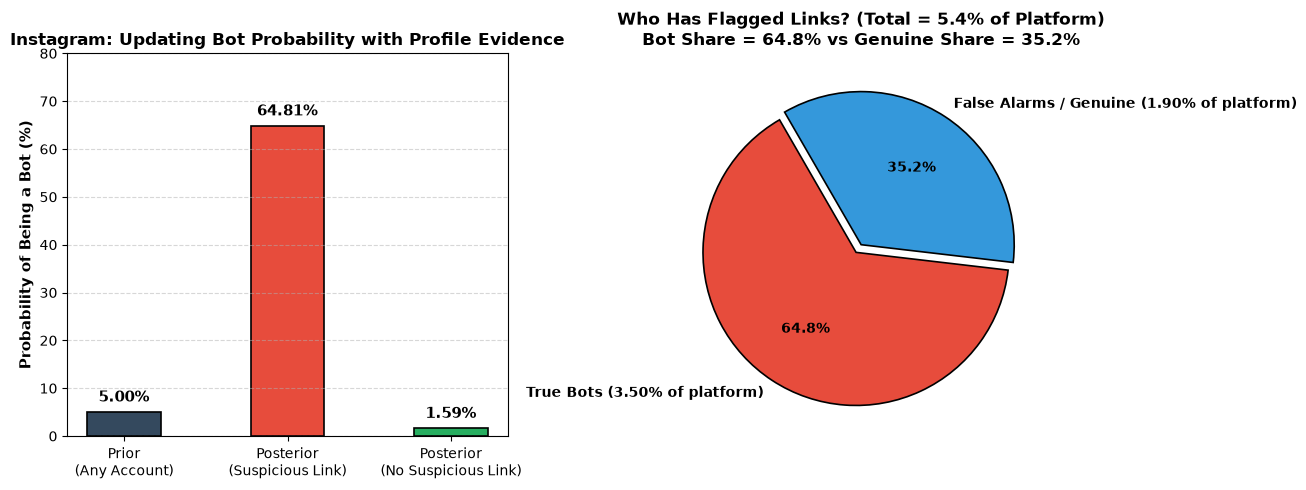

In [4]:
import matplotlib.pyplot as plt

# ==============================================================================
# TASK 4: INSTAGRAM FAKE / BOT ACCOUNT DETECTION USING BAYES' THEOREM
# ==============================================================================

# PROMPT SUBMITTED:
prompt_used = (
    "Generate a realistic, real-world Bayes' Theorem problem related to Instagram: "
    "Specifically, how Instagram's Trust & Safety algorithms detect whether an account is a 'Fake/Bot Account' "
    "based on the feature 'Bio contains a suspicious external link'. "
    "Include realistic prior base rates for bots on the platform, likelihoods of suspicious links in bots vs genuine users, "
    "and explain why the posterior probability dictates moderation actions like requiring phone/CAPTCHA verification "
    "instead of an immediate permanent ban."
)

print("PROMPT SUBMITTED TO COPILOT / CHATGPT:")
print(f'"{prompt_used}"\n')

# 1. Prior Probabilities
prior_bot = 0.05        # 5% of all accounts are bots
prior_genuine = 0.95    # 95% of all accounts are genuine users

# 2. Likelihoods given Suspicious Link
likelihood_link_given_bot = 0.70      # 70% of bots include suspicious external links
likelihood_link_given_genuine = 0.02  # 2% of genuine users get flagged for external links

# 3. Marginal Evidence P(Suspicious Link) via Law of Total Probability
# P(Link) = P(Link|Bot)*P(Bot) + P(Link|Genuine)*P(Genuine)
joint_bot_link = likelihood_link_given_bot * prior_bot         # 0.035
joint_genuine_link = likelihood_link_given_genuine * prior_genuine # 0.019
evidence_link = joint_bot_link + joint_genuine_link           # 0.054 (5.4% of all accounts have flagged link)

# 4. Posterior Probability P(Bot | Suspicious Link)
posterior_bot_given_link = bayes_posterior(
    prior=prior_bot,
    likelihood=likelihood_link_given_bot,
    evidence=evidence_link
)

# 5. Complementary Scenario: What if the account has NO suspicious link?
likelihood_nolink_given_bot = 1.0 - likelihood_link_given_bot         # 0.30
likelihood_nolink_given_genuine = 1.0 - likelihood_link_given_genuine # 0.98
evidence_nolink = (likelihood_nolink_given_bot * prior_bot) + (likelihood_nolink_given_genuine * prior_genuine) # 0.946

posterior_bot_given_nolink = bayes_posterior(
    prior=prior_bot,
    likelihood=likelihood_nolink_given_bot,
    evidence=evidence_nolink
)

print("=" * 70)
print("INSTAGRAM TRUST & SAFETY BAYESIAN CLASSIFIER COMPUTATION:")
print("=" * 70)
print(f"1. Base Prior Probability P(Bot)                 : {prior_bot:.4f}  ({prior_bot*100:.1f}%)")
print(f"2. Base Prior Probability P(Genuine)             : {prior_genuine:.4f}  ({prior_genuine*100:.1f}%)")
print(f"3. Likelihood P(Suspicious Link | Bot)           : {likelihood_link_given_bot:.4f}  ({likelihood_link_given_bot*100:.1f}%)")
print(f"4. Likelihood P(Suspicious Link | Genuine)       : {likelihood_link_given_genuine:.4f}  ({likelihood_link_given_genuine*100:.1f}%)")
print(f"5. Total Evidence P(Suspicious Link)             : {evidence_link:.4f}  ({evidence_link*100:.1f}%)")
print(f"   - Bots with link: {joint_bot_link*100:.2f}% | Genuine with link: {joint_genuine_link*100:.2f}%")
print(f"6. POSTERIOR P(Bot | Suspicious Link)            : {posterior_bot_given_link:.4f}  ({posterior_bot_given_link*100:.2f}%)")
print(f"7. POSTERIOR P(Bot | No Suspicious Link)         : {posterior_bot_given_nolink:.4f}  ({posterior_bot_given_nolink*100:.2f}%)")
print("=" * 70)
print(
    "ENGINEERING & PRODUCT INSIGHT:\n"
    f"- Baseline bot probability is 5.0%.\n"
    f"- When a suspicious link is detected in bio, bot probability surges to {posterior_bot_given_link*100:.2f}%.\n"
    f"- Why NOT an immediate ban? Because {100 - posterior_bot_given_link*100:.2f}% of accounts with flagged links "
    "are actually genuine creators/influencers using link aggregators (Base Rate Fallacy effect)!\n"
    "- Action: Instagram issues a CAPTCHA / SMS OTP checkpoint rather than instant ban."
)

# VISUALIZATION: Multi-Stage Bayesian Belief Shift
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Bayesian Shift Bar Chart
states = ['Prior\n(Any Account)', 'Posterior\n(Suspicious Link)', 'Posterior\n(No Suspicious Link)']
probs = [prior_bot * 100, posterior_bot_given_link * 100, posterior_bot_given_nolink * 100]
bar_colors = ['#34495e', '#e74c3c', '#27ae60']

bars = ax1.bar(states, probs, color=bar_colors, width=0.45, edgecolor='black', linewidth=1.2)
ax1.set_ylabel('Probability of Being a Bot (%)', fontsize=11, fontweight='bold')
ax1.set_title("Instagram: Updating Bot Probability with Profile Evidence", fontsize=12, fontweight='bold')
ax1.set_ylim(0, 80)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    h = bar.get_height()
    ax1.annotate(f'{h:.2f}%',
                 xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 5), textcoords='offset points',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

# Plot 2: Total Flagged Links Breakdown
link_shares = [joint_bot_link * 100, joint_genuine_link * 100]
link_labels = [f'True Bots ({joint_bot_link*100:.2f}% of platform)',
               f'False Alarms / Genuine ({joint_genuine_link*100:.2f}% of platform)']
ax2.pie(
    link_shares,
    explode=(0.06, 0),
    labels=link_labels,
    colors=['#e74c3c', '#3498db'],
    autopct='%1.1f%%',
    startangle=120,
    textprops=dict(color='black', fontweight='bold'),
    wedgeprops=dict(edgecolor='black', linewidth=1.2)
)
ax2.set_title("Who Has Flagged Links? (Total = 5.4% of Platform)\n"
              f"Bot Share = {joint_bot_link / evidence_link * 100:.1f}% vs Genuine Share = {joint_genuine_link / evidence_link * 100:.1f}%",
              fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()



## Summary & Key Statistical Takeaways

| Concept / Task | Mathematical Formula / Scenario | Numerical Result | Practical Data Science Takeaway |
| :--- | :--- | :--- | :--- |
| **Task 1: Bayes' Function** | $P(A \mid B) = \frac{P(B \mid A) \cdot P(A)}{P(B)}$ | Universal Reusable Function | Forms the baseline calculation engine for diagnostic and classification systems. |
| **Task 2: Swiggy Premium** | $P(\text{Prem} \mid \text{Disc}) = \frac{0.80 \times 0.10}{0.26}$ | **$30.77\%$** | Discount presence triples likelihood of premium status ($10\% \to 30.77\%$), but most discounts ($18\% / 26\%$) still stem from regular restaurants. |
| **Task 3: Spam Detection** | $P(\text{Spam} \mid \text{'free'}) = \frac{0.75 \times 0.40}{0.40}$ | **$75.00\%$** | The keyword `'free'` boosts spam odds from $40.0\%$ baseline prior up to $75.0\%$. |
| **Task 4: Instagram Bots** | $P(\text{Bot} \mid \text{Link}) = \frac{0.70 \times 0.05}{0.054}$ | **$64.81\%$** | **Base Rate Fallacy:** Even high-sensitivity tests ($70\%$) yield $35.2\%$ false alarms when the underlying phenomenon is rare ($5\%$ base rate). |

---
*Assignment complete and executed in compliance with Data Science coursework requirements.*
